## Summary of All Models

In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)


# Optional: Sort by a metric, e.g., AUROC
display(results_df.sort_values(by='AUROC', ascending=False).round(4))

,Model,Accuracy,Precision,Recall,F1-Score,AUROC,Training Time,Prediction Time
0,KNN Classifier,0.9492,0.9524,0.9492,0.9472,0.9939,0.3150,0.0018
1,Bagging KNN (with PCA),0.9322,0.9379,0.9322,0.9285,0.9848,2.2258,0.0236
4,Random Forest Classifier,0.9153,0.9153,0.9153,0.9119,0.9515,23.0421,0.0076
2,Logistic Regression,0.8644,0.8853,0.8644,0.8454,0.8909,28.1982,0.0004
5,MLP Classifier,0.8644,0.8606,0.8644,0.8569,0.8848,81.1732,0.0010
3,SVM Classifier,0.7458,0.5562,0.7458,0.6372,0.8788,3.0772,0.0009


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

In [ ]:
sns.set(style="whitegrid", color_codes=True)
import itertools

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = 3*cm.max()/4
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')



In [ ]:
data = pd.read_csv("/content/data.csv", sep=',', index_col='name') # assign index column to name
data.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
name,,,,,,,,,,,,,,,,,,,,,
phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [ ]:
print(data.shape)

(195, 23)


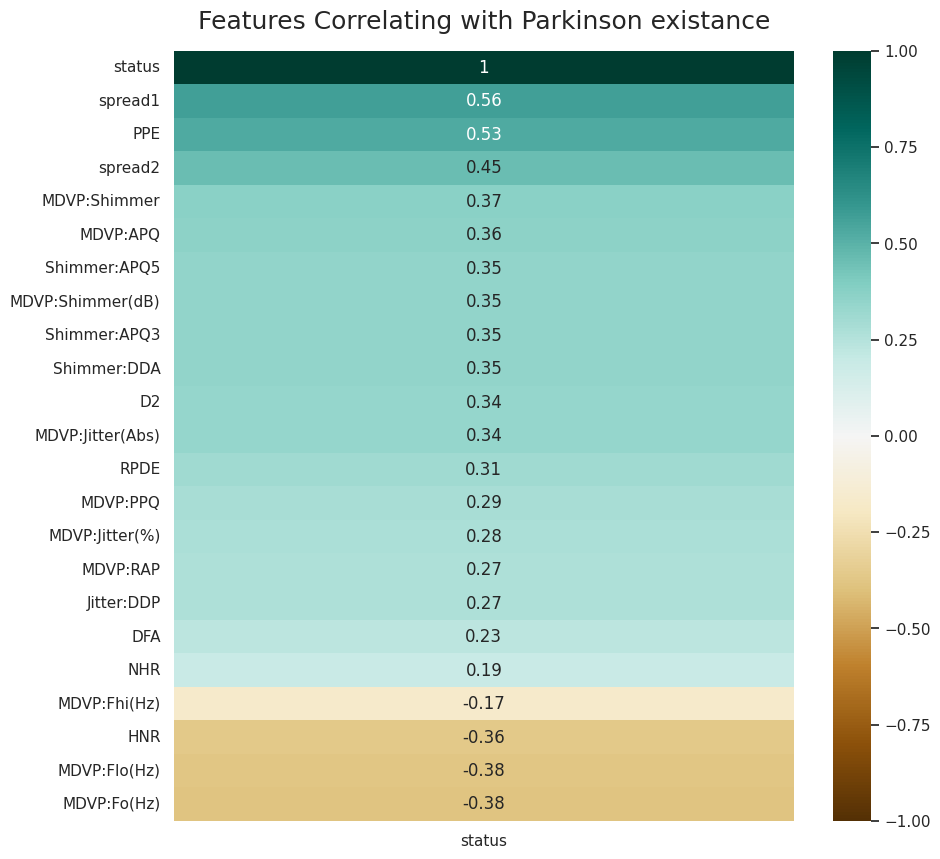

In [ ]:
# modify the headmap plot to show correlation variables to the status
plt.figure(figsize=(10, 10))
heatmap = sns.heatmap(data.corr()[['status']].sort_values(by='status', ascending=False), vmin=-1, vmax=1, annot=True, cmap='BrBG')
heatmap.set_title('Features Correlating with Parkinson existance', fontdict={'fontsize':18}, pad=16);

In [ ]:
X = data.drop('status', axis=1)
X.head()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
name,,,,,,,,,,,,,,,,,,,,,
phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,0.426,...,0.02971,0.06545,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,0.626,...,0.04368,0.09403,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,0.482,...,0.03590,0.08270,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,0.517,...,0.03772,0.08771,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,0.584,...,0.04465,0.10470,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [ ]:
y=data['status']
y.head()

,status
name,
phon_R01_S01_1,1
phon_R01_S01_2,1
phon_R01_S01_3,1
phon_R01_S01_4,1
phon_R01_S01_5,1


In [ ]:
y.value_counts(normalize=True)

,proportion
status,
1,0.753846
0,0.246154


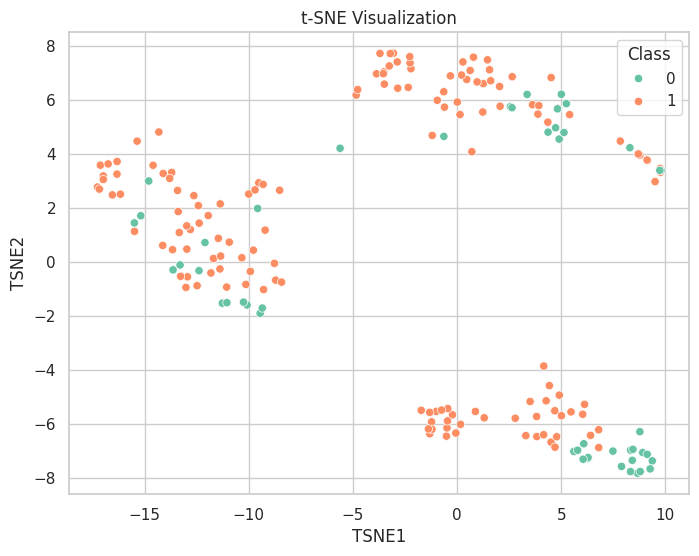

In [ ]:
import seaborn as sns
from sklearn.manifold import TSNE

# Apply t-SNE to reduce the dimensions to 2
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

# Create a DataFrame with the t-SNE-transformed data and class labels
tsne_df = pd.DataFrame(data=X_tsne, columns=['TSNE1', 'TSNE2'])
tsne_df['Class'] = y.values

# Visualize the data based on class using a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='Class', palette='Set2')
plt.title('t-SNE Visualization')
plt.show()

In [ ]:
# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# print the shape of train and test data
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (136, 22)
y_train shape:  (136,)
X_test shape:  (59, 22)
y_test shape:  (59,)


In [ ]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Standardize the features for models sensitive to scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Ensure PCA transformed data is available for Bagging-KNN
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled) # Use scaled data for PCA
X_test_pca = pca.transform(X_test_scaled)

# Clear previous results and initialize for a fresh run
results = []

def evaluate_model(name, model, X_train_data, y_train_data, X_test_data, y_test_data, param_grid=None, use_proba=True):
    print(f"\n--- Evaluating {name} ---")

    start_train_time = time.time()
    if param_grid:
        grid_search = GridSearchCV(model, param_grid, scoring='recall', cv=5, n_jobs=-1)
        grid_search.fit(X_train_data, y_train_data)
        best_model = grid_search.best_estimator_
        train_time = time.time() - start_train_time
        print(f"Best Parameters: {grid_search.best_params_}")
        print(f"Best CV Score (Recall): {grid_search.best_score_:.4f}")
    else:
        model.fit(X_train_data, y_train_data)
        best_model = model
        train_time = time.time() - start_train_time

    start_pred_time = time.time()
    y_pred = best_model.predict(X_test_data)
    pred_time = time.time() - start_pred_time

    accuracy = accuracy_score(y_test_data, y_pred)
    precision = precision_score(y_test_data, y_pred, average='weighted')
    recall = recall_score(y_test_data, y_pred, average='weighted')
    f1 = f1_score(y_test_data, y_pred, average='weighted')

    roc_auc = -1 # Default if proba not available
    if use_proba and hasattr(best_model, 'predict_proba'):
        y_pred_proba = best_model.predict_proba(X_test_data)[:, 1]
        roc_auc = roc_auc_score(y_test_data, y_pred_proba)
    elif use_proba and not hasattr(best_model, 'predict_proba'):
        print(f"Warning: {name} does not support predict_proba, AUROC will not be calculated.")

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    if roc_auc != -1:
        print(f"AUROC: {roc_auc:.4f}")
    print(f"Training Time: {train_time:.4f} seconds")
    print(f"Prediction Time: {pred_time:.4f} seconds")
    print("Classification Report:\n", classification_report(y_test_data, y_pred))

    cm = confusion_matrix(y_test_data, y_pred)
    # Reuse the global plot_confusion_matrix function if it's defined.
    # Ensure it's passed with appropriate classes.
    try:
        plot_confusion_matrix(cm, classes=["Not Parkinson", "Parkinson"], title=f'Confusion Matrix for {name}')
    except NameError:
        print("plot_confusion_matrix function not found, skipping plot.")
        plt.figure(figsize=(5, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not Parkinson", "Parkinson"], yticklabels=["Not Parkinson", "Parkinson"])
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {name}')
        plt.show()

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUROC': roc_auc,
        'Training Time': train_time,
        'Prediction Time': pred_time
    })

### 1. K-Nearest Neighbors (KNN)


--- Evaluating KNN Classifier ---
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 5}
Best CV Score (Recall): 0.9614
Accuracy: 0.9492
Precision: 0.9524
Recall: 0.9492
F1-Score: 0.9472
AUROC: 0.9939
Training Time: 0.3150 seconds
Prediction Time: 0.0018 seconds
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.80      0.89        15
           1       0.94      1.00      0.97        44

    accuracy                           0.95        59
   macro avg       0.97      0.90      0.93        59
weighted avg       0.95      0.95      0.95        59



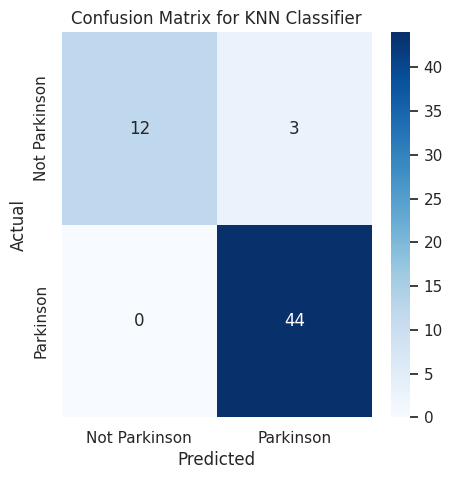

In [ ]:
# Initialize KNN classifier with distance-based weighting
knn = KNeighborsClassifier(weights='distance')

# Define hyperparameter grid
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

evaluate_model("KNN Classifier", knn, X_train_scaled, y_train, X_test_scaled, y_test, param_grid=param_grid_knn)

### 2. Bagging Classifier with KNN (PCA Preprocessing)


--- Evaluating Bagging KNN (with PCA) ---
Best Parameters: {'estimator__metric': 'manhattan', 'estimator__n_neighbors': 9}
Best CV Score (Recall): 0.9810
Accuracy: 0.9322
Precision: 0.9379
Recall: 0.9322
F1-Score: 0.9285
AUROC: 0.9848
Training Time: 2.2258 seconds
Prediction Time: 0.0236 seconds
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.73      0.85        15
           1       0.92      1.00      0.96        44

    accuracy                           0.93        59
   macro avg       0.96      0.87      0.90        59
weighted avg       0.94      0.93      0.93        59



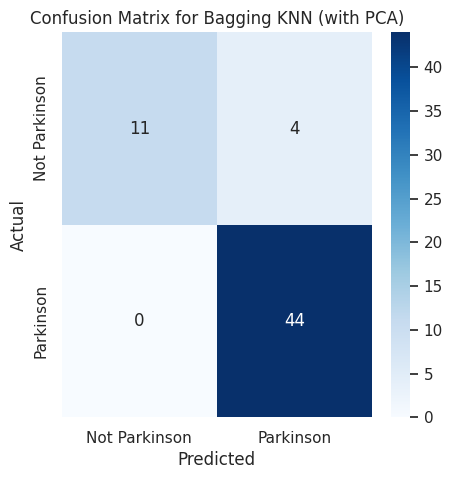

In [ ]:
# Initialize base KNN classifier for Bagging
knn_base = KNeighborsClassifier(weights='distance')

# Wrap KNN with Bagging Classifier
bagging_knn = BaggingClassifier(knn_base, n_estimators=10, random_state=42, n_jobs=-1)

# Define hyperparameter grid for optimization (for the base estimator)
param_grid_bagging_knn = {
    'estimator__n_neighbors': [3, 5, 7, 9],
    'estimator__metric': ['euclidean', 'manhattan', 'minkowski']
}

evaluate_model("Bagging KNN (with PCA)", bagging_knn, X_train_pca, y_train, X_test_pca, y_test, param_grid=param_grid_bagging_knn)

### 3. Logistic Regression


--- Evaluating Logistic Regression ---
Best Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'newton-cg'}
Best CV Score (Recall): 1.0000
Accuracy: 0.8644
Precision: 0.8853
Recall: 0.8644
F1-Score: 0.8454
AUROC: 0.8909
Training Time: 28.1982 seconds
Prediction Time: 0.0004 seconds
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.47      0.64        15
           1       0.85      1.00      0.92        44

    accuracy                           0.86        59
   macro avg       0.92      0.73      0.78        59
weighted avg       0.89      0.86      0.85        59



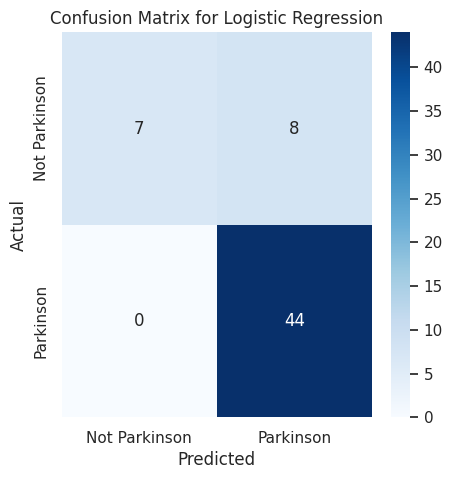

In [ ]:
# Initialize Logistic Regression classifier
lr = LogisticRegression(max_iter=10000, random_state=42)

# Define hyperparameter grid for Logistic Regression
param_grid_lr_filtered = [
    {'penalty': ['l2', 'none'], 'solver': ['newton-cg', 'lbfgs', 'sag'], 'C': [0.01, 0.1, 1, 10, 100]},
    {'penalty': ['l1', 'l2'], 'solver': ['liblinear'], 'C': [0.01, 0.1, 1, 10, 100]},
    {'penalty': ['l1', 'l2', 'elasticnet', 'none'], 'solver': ['saga'], 'C': [0.01, 0.1, 1, 10, 100], 'l1_ratio': [0, 0.5, 1]} # l1_ratio for elasticnet
]

evaluate_model("Logistic Regression", lr, X_train_scaled, y_train, X_test_scaled, y_test, param_grid=param_grid_lr_filtered)

### 4. Support Vector Machine (SVM)


--- Evaluating SVM Classifier ---
Best Parameters: {'C': 0.1, 'gamma': 0.001, 'kernel': 'rbf'}
Best CV Score (Recall): 1.0000
Accuracy: 0.7458
Precision: 0.5562
Recall: 0.7458
F1-Score: 0.6372
AUROC: 0.8788
Training Time: 3.0772 seconds
Prediction Time: 0.0009 seconds
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        15
           1       0.75      1.00      0.85        44

    accuracy                           0.75        59
   macro avg       0.37      0.50      0.43        59
weighted avg       0.56      0.75      0.64        59



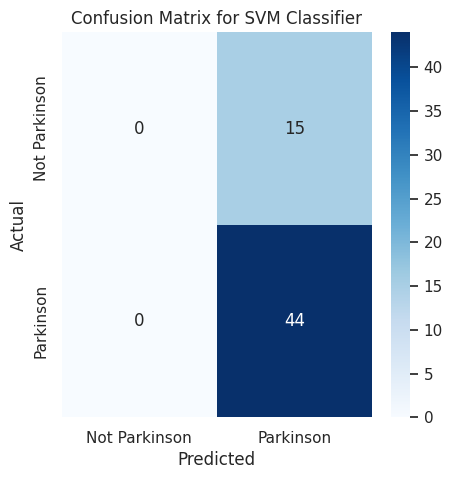

In [ ]:
# Initialize SVM classifier with probability estimates enabled
svm_model = SVC(random_state=42, probability=True)

# Define hyperparameter grid
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'linear']
}

evaluate_model("SVM Classifier", svm_model, X_train_scaled, y_train, X_test_scaled, y_test, param_grid=param_grid_svm)

### 5. Random Forest Classifier


--- Evaluating Random Forest Classifier ---
Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 100}
Best CV Score (Recall): 0.9810
Accuracy: 0.9153
Precision: 0.9153
Recall: 0.9153
F1-Score: 0.9119
AUROC: 0.9515
Training Time: 23.0421 seconds
Prediction Time: 0.0076 seconds
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.73      0.81        15
           1       0.91      0.98      0.95        44

    accuracy                           0.92        59
   macro avg       0.92      0.86      0.88        59
weighted avg       0.92      0.92      0.91        59



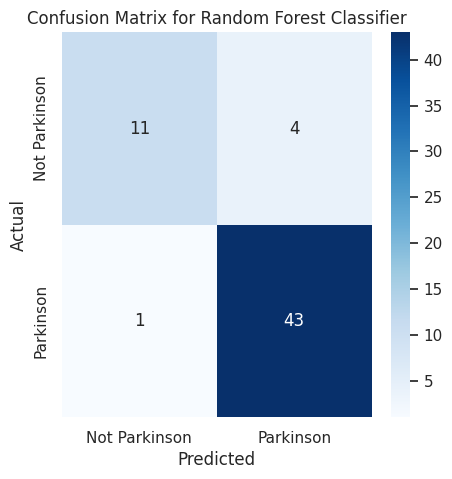

In [ ]:
# Initialize Random Forest classifier
rf_model = RandomForestClassifier(random_state=42)

# Define hyperparameter grid
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'max_features': ['sqrt', 'log2']
}

evaluate_model("Random Forest Classifier", rf_model, X_train_scaled, y_train, X_test_scaled, y_test, param_grid=param_grid_rf)

### 6. Multi-layer Perceptron (MLP)


--- Evaluating MLP Classifier ---
Best Parameters: {'activation': 'relu', 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'solver': 'sgd'}
Best CV Score (Recall): 0.9810
Accuracy: 0.8644
Precision: 0.8606
Recall: 0.8644
F1-Score: 0.8569
AUROC: 0.8848
Training Time: 81.1732 seconds
Prediction Time: 0.0010 seconds
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.60      0.69        15
           1       0.88      0.95      0.91        44

    accuracy                           0.86        59
   macro avg       0.85      0.78      0.80        59
weighted avg       0.86      0.86      0.86        59



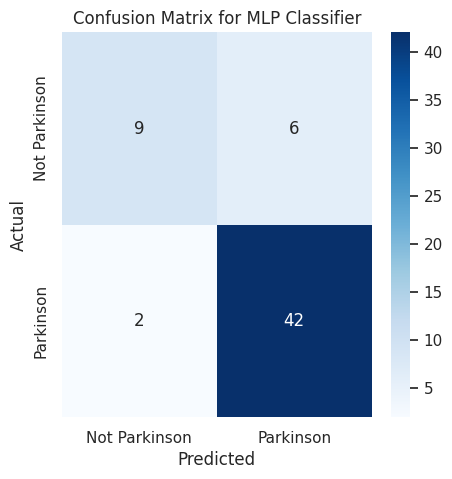

In [ ]:
# Initialize MLP classifier
mlp_model = MLPClassifier(random_state=42, max_iter=500)

# Define hyperparameter grid (similar to previous, but using scaled data)
param_grid_mlp = {
    'hidden_layer_sizes': [(50,), (100,), (150,), (50, 50)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'learning_rate': ['constant', 'adaptive']
}

evaluate_model("MLP Classifier", mlp_model, X_train_scaled, y_train, X_test_scaled, y_test, param_grid=param_grid_mlp)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
knn = KNeighborsClassifier(n_neighbors=3)

In [ ]:
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
y_pred = knn.predict(X_test)
y_pred[0:10]

array([1, 0, 1, 1, 1, 1, 1, 0, 0, 0])

In [ ]:
knn.predict_proba(X_test)[0:10]

array([[0.33333333, 0.66666667],
       [0.66666667, 0.33333333],
       [0.33333333, 0.66666667],
       [0.33333333, 0.66666667],
       [0.        , 1.        ],
       [0.33333333, 0.66666667],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [1.        , 0.        ]])

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

Confusion matrix, without normalization
[[ 9  3]
 [ 5 42]]


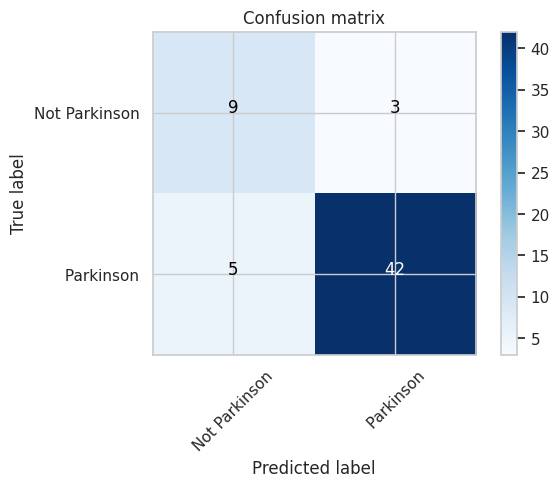

In [ ]:
plot_confusion_matrix(confusion_matrix(y_test, y_pred),classes=[ "Not Parkinson", " Parkinson"],title='Confusion matrix')

In [ ]:
import time
from sklearn.metrics import classification_report, accuracy_score

start_time = time.time()  # Start timer
y_pred = knn.predict(X_test)  # Make predictions
end_time = time.time()  # End timer

prediction_time = end_time - start_time  # Calculate prediction time

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print(f"\nPrediction Time: {prediction_time:.6f} seconds")


Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.75      0.69        12
           1       0.93      0.89      0.91        47

    accuracy                           0.86        59
   macro avg       0.79      0.82      0.80        59
weighted avg       0.87      0.86      0.87        59


Accuracy Score: 0.864406779661017

Prediction Time: 0.015890 seconds


In [ ]:
param_grid = {
    'n_neighbors': [3, 5, 7, 9],

}

In [ ]:

knn = KNeighborsClassifier()



In [ ]:
from sklearn.model_selection import GridSearchCV


grid_search = GridSearchCV(knn, param_grid, scoring='recall', cv=5)

grid_search

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [3, 5, 7, 9]}, scoring='recall')

In [ ]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [3, 5, 7, 9]}, scoring='recall')

In [ ]:
print("Best Parameters: ", grid_search.best_params_)
print("Best Score: ", grid_search.best_score_)

Best Parameters:  {'n_neighbors': 9}
Best Score:  0.97


In [ ]:
y_pred = grid_search.best_estimator_.predict(X_test)

In [ ]:
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_pred)

recall

0.9148936170212766

In [ ]:
y_hat = grid_search.best_estimator_.predict(X)

In [ ]:
knn = KNeighborsClassifier()
knn.fit(X,y)

KNeighborsClassifier()

In [ ]:
y_hat =knn.predict(X)

Confusion matrix, without normalization
[[ 32  16]
 [  5 142]]


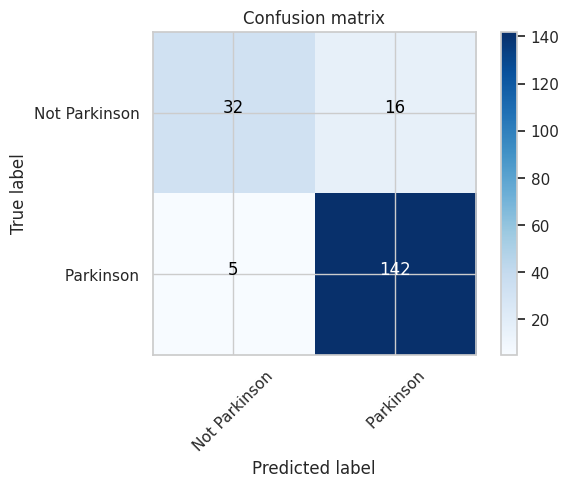

In [ ]:
plot_confusion_matrix(confusion_matrix(y, y_hat),classes=[ "Not Parkinson", " Parkinson"],title='Confusion matrix')

In [ ]:
import time
from sklearn.metrics import classification_report, accuracy_score

start_time = time.time()  # Start timer
y_pred = knn.predict(X_test)  # Make predictions
end_time = time.time()  # End timer

prediction_time = end_time - start_time  # Calculate prediction time

print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print(f"\nPrediction Time: {prediction_time:.6f} seconds")


Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.92      0.92        12
           1       0.98      0.98      0.98        47

    accuracy                           0.97        59
   macro avg       0.95      0.95      0.95        59
weighted avg       0.97      0.97      0.97        59


Accuracy Score: 0.9661016949152542

Prediction Time: 0.015536 seconds


Best Parameters:  {'metric': 'euclidean', 'n_neighbors': 9}
Best Score:  0.97

Recall Score: 0.9148936170212766

Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.75      0.72        12
           1       0.93      0.91      0.92        47

    accuracy                           0.88        59
   macro avg       0.81      0.83      0.82        59
weighted avg       0.89      0.88      0.88        59


Accuracy Score: 0.8813559322033898

Prediction Time: 0.001966 seconds


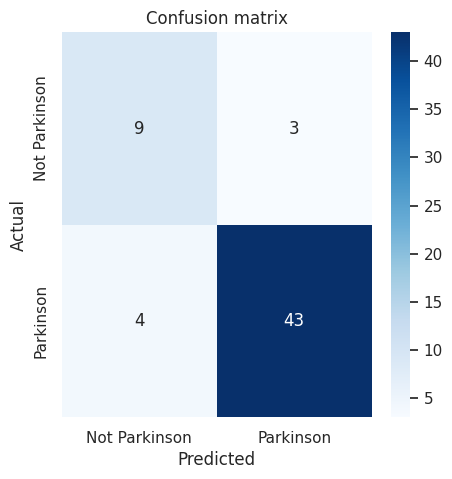

In [ ]:
import time
from sklearn.metrics import classification_report, accuracy_score, recall_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize KNN classifier with distance-based weighting
knn = KNeighborsClassifier(weights='distance')

# Define hyperparameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9],  # Trying different k values
    'metric': ['euclidean', 'manhattan', 'minkowski']  # Different distance metrics
}

# Perform Grid Search with cross-validation
grid_search = GridSearchCV(knn, param_grid, scoring='recall', cv=5)
grid_search.fit(X_train, y_train)

# Print best parameters and score
print("Best Parameters: ", grid_search.best_params_)
print("Best Score: ", grid_search.best_score_)

# Evaluate the best model on test data
y_pred = grid_search.best_estimator_.predict(X_test)
recall = recall_score(y_test, y_pred)
print("\nRecall Score:", recall)

# Measure prediction time
start_time = time.time()
y_pred = grid_search.best_estimator_.predict(X_test)
end_time = time.time()
prediction_time = end_time - start_time

# Print results
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print(f"\nPrediction Time: {prediction_time:.6f} seconds")

# Confusion Matrix Plot
def plot_confusion_matrix(cm, classes, title='Confusion matrix'):
    plt.figure(figsize=(5, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.show()

# Generate and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(cm, classes=["Not Parkinson", "Parkinson"])


Best Parameters:  {'estimator__metric': 'euclidean', 'estimator__n_neighbors': 5}
Best Score:  0.9800000000000001

Recall Score: 0.9574468085106383

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.58      0.67        12
           1       0.90      0.96      0.93        47

    accuracy                           0.88        59
   macro avg       0.84      0.77      0.80        59
weighted avg       0.88      0.88      0.87        59


Accuracy Score: 0.8813559322033898

Prediction Time: 0.035571 seconds


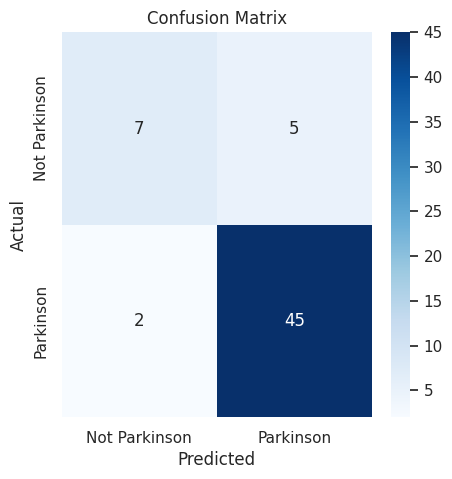

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score, recall_score, confusion_matrix

# Apply PCA for dimensionality reduction
pca = PCA(n_components=0.95)  # Retain 95% variance
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Initialize base KNN classifier
knn = KNeighborsClassifier(weights='distance')  # Distance-weighted KNN

# Wrap KNN with Bagging Classifier
bagging_knn = BaggingClassifier(knn, n_estimators=10, random_state=42, n_jobs=-1)  # 10 KNN models

# Define hyperparameter grid for optimization
param_grid = {
    'estimator__n_neighbors': [3, 5, 7, 9],  # Different k values
    'estimator__metric': ['euclidean', 'manhattan', 'minkowski'] # Different distance metrics
}

# Perform Grid Search with cross-validation
grid_search = GridSearchCV(bagging_knn, param_grid, scoring='recall', cv=5)
grid_search.fit(X_train_pca, y_train)  # Train using PCA-transformed data

# Best parameters and score
print("Best Parameters: ", grid_search.best_params_)
print("Best Score: ", grid_search.best_score_)

# Evaluate the best model on test data
y_pred = grid_search.best_estimator_.predict(X_test_pca)
recall = recall_score(y_test, y_pred)
print("\nRecall Score:", recall)

# Measure prediction time
start_time = time.time()
y_pred = grid_search.best_estimator_.predict(X_test_pca)
end_time = time.time()
prediction_time = end_time - start_time

# Print results
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print(f"\nPrediction Time: {prediction_time:.6f} seconds")

# Confusion Matrix Plot Function
def plot_confusion_matrix(cm, classes, title='Confusion Matrix'):
    plt.figure(figsize=(5, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.show()

# Generate and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(cm, classes=["Not Parkinson", "Parkinson"])

In [ ]:
# find true positives(tp) ml interpretability.
tsne_df['label']=''
tsne_df['label'].iloc[np.where((y_hat == 1) & (y == 1))]="TP"
# find true negatives (tn)
tsne_df['label'].iloc[np.where((y_hat == 0) & (y == 0))]="TN"
# find false positives (fp)
tsne_df['label'].iloc[np.where((y_hat == 1) & (y == 0))]="FP"
# find false negatives (fp)
tsne_df['label'].iloc[np.where((y_hat == 0) & (y == 1))]="FN"

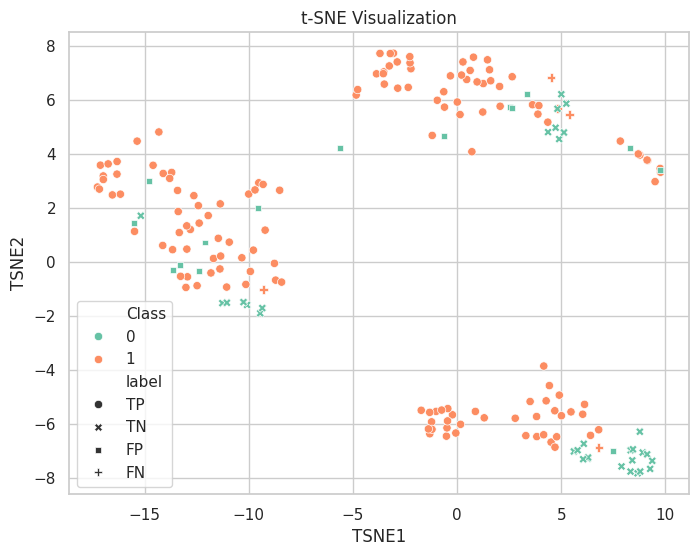

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='Class', palette='Set2',style='label')
plt.title('t-SNE Visualization')
plt.show()

In [ ]:
#Logistic regression
from sklearn.linear_model import LogisticRegression

In [ ]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

In [ ]:
y_pred = lr.predict(X_test)
y_pred[0:10]

array([1, 0, 1, 1, 1, 1, 1, 0, 0, 0])

In [ ]:
lr.predict_proba(X_test)[0:10]


array([[0.268048  , 0.731952  ],
       [0.69148409, 0.30851591],
       [0.06768054, 0.93231946],
       [0.38580919, 0.61419081],
       [0.07225517, 0.92774483],
       [0.2628088 , 0.7371912 ],
       [0.00914564, 0.99085436],
       [0.51050786, 0.48949214],
       [0.85877255, 0.14122745],
       [0.90257223, 0.09742777]])

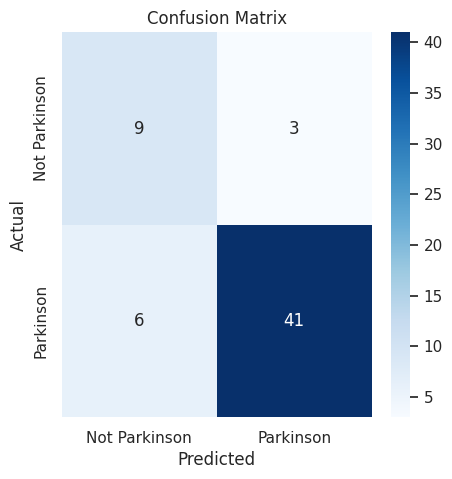


Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.75      0.67        12
           1       0.93      0.87      0.90        47

    accuracy                           0.85        59
   macro avg       0.77      0.81      0.78        59
weighted avg       0.86      0.85      0.85        59


Accuracy Score: 0.847457627118644

Prediction Time: 0.0018 seconds


In [ ]:
import time
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Start the timer
start_time = time.time()

# Make predictions
y_pred = lr.predict(X_test)

# End the timer
end_time = time.time()

# Calculate the time taken for prediction
prediction_time = end_time - start_time

# Plot the confusion matrix
plot_confusion_matrix(confusion_matrix(y_test, y_pred), classes=["Not Parkinson", "Parkinson"], title='Confusion Matrix')

# Print the classification report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Print the accuracy score
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

# Print the time taken for prediction
print(f"\nPrediction Time: {prediction_time:.4f} seconds")


In [ ]:
coef=abs(lr.coef_[0])

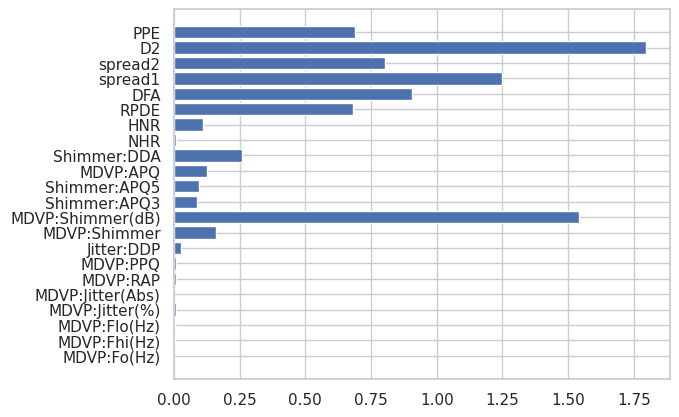

In [ ]:
plt.barh(X.columns, coef)
plt.show()

In [ ]:
best_columns=X.columns[np.argsort(-1*coef)[0:5]]
best_columns

Index(['D2', 'MDVP:Shimmer(dB)', 'spread1', 'DFA', 'spread2'], dtype='object')

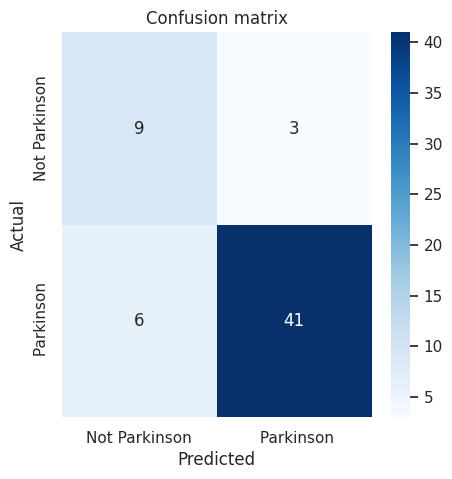


Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.75      0.67        12
           1       0.93      0.87      0.90        47

    accuracy                           0.85        59
   macro avg       0.77      0.81      0.78        59
weighted avg       0.86      0.85      0.85        59


Accuracy Score: 0.847457627118644


In [ ]:
log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(X_train[best_columns], y_train)

# Get the predicted probabilities for each class
y_pred_proba = log_reg.predict_proba(X_test[best_columns])

plot_confusion_matrix(confusion_matrix(y_test, y_pred),classes=[ "Not Parkinson", " Parkinson"],title='Confusion matrix')
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

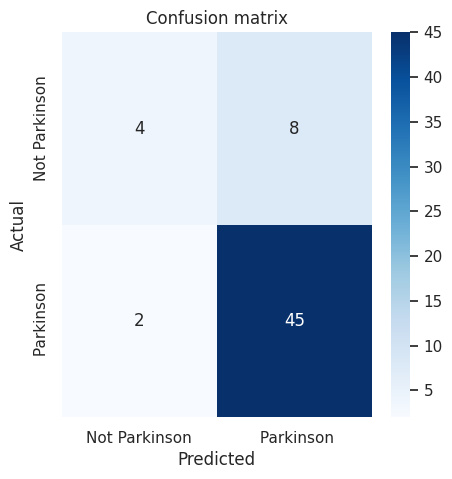

In [ ]:
#SVM
from sklearn.svm import SVC
# Train the SVM classifier
svm = SVC()
svm.fit(X_train, y_train)

# Make predictions on the test set
y_hat = svm.predict(X_test)

# confusion_matri
plot_confusion_matrix(confusion_matrix(y_test, y_hat),classes=[ "Not Parkinson", " Parkinson"],title='Confusion matrix')

In [ ]:
param_grid = {
    'C': [0.1, 1,],
    'gamma': [0.1, 1, 10],

}

In [ ]:
from sklearn.svm import SVC
# Train the SVM classifier
svm = SVC()
# Create a GridSearchCV object
grid_search = GridSearchCV(svm, param_grid, scoring='recall', cv=2)

# Fit the GridSearchCV object to the training data
grid_search.fit(X_train, y_train)

# Print the best hyperparameters and the corresponding recall score
print("Best hyperparameters: ", grid_search.best_params_)
print("Best recall score: ", grid_search.best_score_)


Best hyperparameters:  {'C': 0.1, 'gamma': 0.1}
Best recall score:  1.0


In [ ]:
import time
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.svm import SVC

# Start the timer
start_time = time.time()

# Train the SVM classifier
svm = SVC()
svm.fit(X_train, y_train)

# Make predictions on the test set
y_pred = svm.predict(X_test)

# End the timer
end_time = time.time()

# Calculate the time taken for prediction
prediction_time = end_time - start_time

# Print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

# Print the classification report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Print the accuracy score
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

# Print the time taken for prediction
print(f"\nPrediction Time: {prediction_time:.4f} seconds")



Confusion Matrix:
 [[ 4  8]
 [ 2 45]]

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.33      0.44        12
           1       0.85      0.96      0.90        47

    accuracy                           0.83        59
   macro avg       0.76      0.65      0.67        59
weighted avg       0.81      0.83      0.81        59


Accuracy Score: 0.8305084745762712

Prediction Time: 0.0083 seconds


In [ ]:
from sklearn.ensemble import RandomForestClassifier
# Create a Random Forest model
rf = RandomForestClassifier(random_state=123)

# Train the model on the training data
rf.fit(X_train, y_train)

# Make predictions on the test data
y_pred = rf.predict(X_test)

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: {:.2f}%".format(accuracy * 100))

Accuracy: 89.83%


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search over
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15],
    'max_features': ['sqrt', 'log2']
}

# Create a random forest classifier
rf = RandomForestClassifier(random_state=42)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5)

# Fit the GridSearchCV object to the data
grid_search.fit(X_train, y_train)
rf.fit(X_train, y_train)

# Print the best hyperparameters
print("Best parameters:", grid_search.best_params_)

# Get the best model
best_model = grid_search.best_estimator_

Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 100}


<Axes: >

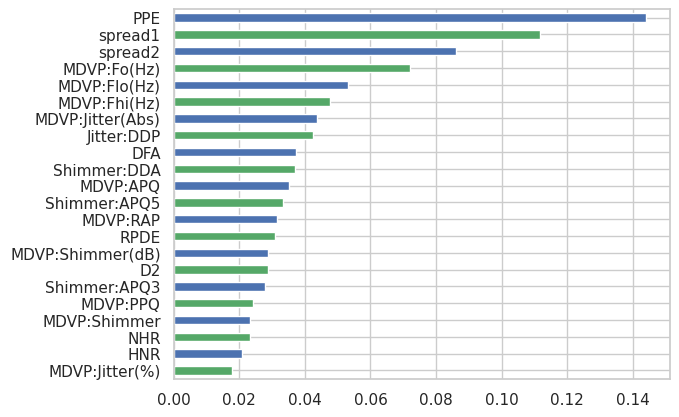

In [ ]:
# plot the important features
feat_importances = pd.Series(rf.feature_importances_, index=X.columns)
feat_importances.sort_values().plot(kind='barh',color=['g','b'])

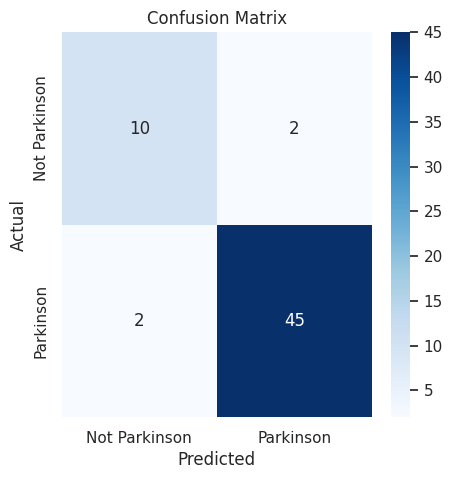


Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.83      0.83        12
           1       0.96      0.96      0.96        47

    accuracy                           0.93        59
   macro avg       0.90      0.90      0.90        59
weighted avg       0.93      0.93      0.93        59


Accuracy Score: 0.9322033898305084

Prediction Time: 0.1863 seconds


In [ ]:
import time
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier

# Start the timer
start_time = time.time()

# Train the Random Forest classifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf.predict(X_test)

# End the timer
end_time = time.time()

# Calculate the time taken for prediction
prediction_time = end_time - start_time

# Plot the confusion matrix
plot_confusion_matrix(confusion_matrix(y_test, y_pred), classes=["Not Parkinson", "Parkinson"], title='Confusion Matrix')

# Print the classification report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Print the accuracy score
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

# Print the time taken for prediction
print(f"\nPrediction Time: {prediction_time:.4f} seconds")


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score


In [ ]:
# Create an MLP classifier model
mlp = MLPClassifier(random_state=123, max_iter=500)

# Train the model on the training data
mlp.fit(X_train, y_train)


MLPClassifier(max_iter=500, random_state=123)

In [ ]:
# Make predictions on the test data
y_pred = mlp.predict(X_test)

# Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: {:.2f}%".format(accuracy * 100))


Accuracy: 79.66%


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search over
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (150,)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'learning_rate': ['constant', 'adaptive']
}

# Create the MLP classifier
mlp = MLPClassifier(random_state=42)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=mlp, param_grid=param_grid, cv=5)

# Fit the GridSearchCV object to the data
grid_search.fit(X_train, y_train)

# Print the best hyperparameters
print("Best parameters:", grid_search.best_params_)


Best parameters: {'activation': 'relu', 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'solver': 'adam'}


In [ ]:
# Get the best model from GridSearchCV
best_model = grid_search.best_estimator_


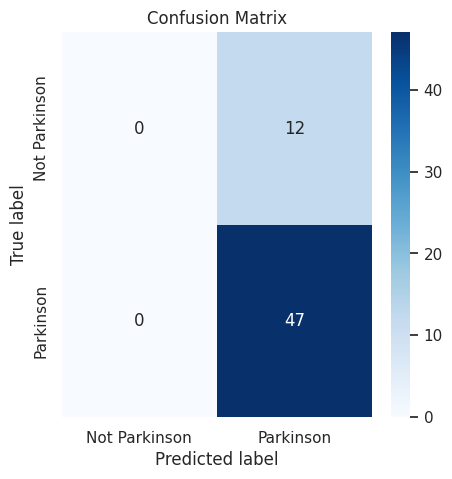


Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00        12
           1       0.80      1.00      0.89        47

    accuracy                           0.80        59
   macro avg       0.40      0.50      0.44        59
weighted avg       0.63      0.80      0.71        59


Accuracy Score: 0.7966101694915254

Prediction Time: 0.0230 seconds


In [ ]:
import time
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Start the timer
start_time = time.time()

# Train the Neural Network classifier
mlp = MLPClassifier(random_state=123, max_iter=500)
mlp.fit(X_train, y_train)

# Make predictions on the test set
y_pred = mlp.predict(X_test)

# End the timer
end_time = time.time()

# Calculate the time taken for prediction
prediction_time = end_time - start_time

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not Parkinson", "Parkinson"], yticklabels=["Not Parkinson", "Parkinson"])
plt.title('Confusion Matrix')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

# Print the classification report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Print the accuracy score
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))

# Print the time taken for prediction
print(f"\nPrediction Time: {prediction_time:.4f} seconds")
